# Notebook 6 — Stage 2: Honest Validation and a Longer Rolling Window

Notebooks 1–5 are **Stage 1**: they built the baseline with a **5-cycle** rolling window. They are kept unchanged so that the improvement can be measured against them.

This notebook is **Stage 2**. It shows, step by step:

| Step | Question | Answer in one line |
|---|---|---|
| 1 | Why did Stage 1 look better in validation than on the test set? | Test engines stop early, so their "fails soon" rows are the hard ones |
| 2 | How do we validate fairly? | Cut validation engines early, the way test engines are cut, and repeat 5 times |
| 3 | Did anything leak? Was tuning worth it? | No leak found; tuning made no measurable difference |
| 4 | What is the improvement? | A **40-cycle** rolling window instead of 5 |
| 5 | Why does it work? | Over 40 cycles, the spread of a sensor measures how fast the engine is wearing |
| 6 | Which model, which settings? | Plain logistic regression, C = 0.01, threshold 0.5 |
| 7 | How good is it on the 100 unseen test engines? | F1 0.706 → **0.870**; failing engines caught 18 → **25 of 25** |
| 8 | What does the model look at, and how does it decide? | How fast the compressor pressure sensors are changing |

**How this notebook gets its numbers.** The slow experiments (4 models × 5 repeats × 6 window lengths) take about 20 minutes, so they were run once by the scripts in `improved_implementation/src/` and every result was saved as one row of `improved_implementation/results.csv`. This notebook **reads** those rows, and **re-computes the key numbers live** (they finish in seconds) to show that they reproduce.

In [1]:
import sys, json, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)

STAGE2 = Path("../improved_implementation")
sys.path.insert(0, str(STAGE2 / "src"))
from pm.common import SENSORS, load_config, load_raw, add_rolling, clf_metrics, truncation_index, grouped_folds
from pm.models import make_classifier, n_params

cfg = load_config()                          # Stage 1 settings, copied from notebooks 3-5 (label, drop rule, C, ...)
res = pd.read_csv(STAGE2 / "results.csv")    # every Stage 2 experiment: one row per model, repeat and data split
SEED = 42                                    # the seed used in Stage 1; Stage 2 repeats with 42, 43, 44, 45, 46

ORDER = ["logistic_regression", "decision_tree", "random_forest", "gradient_boosting"]
NICE = {"logistic_regression": "Logistic Regression", "decision_tree": "Decision Tree",
        "random_forest": "Random Forest", "gradient_boosting": "Gradient Boosting"}
COL = {"logistic_regression": "#1f77b4", "decision_tree": "#7f7f7f",
       "random_forest": "#2ca02c", "gradient_boosting": "#ff7f0e"}

def mean_sd(s):
    """'mean ± standard deviation' over the 5 repeats."""
    return f"{s.mean():.3f} ± {s.std():.3f}"

def with_window(window, kinds=("raw", "mean", "std")):
    """The Stage 1 configuration with a different rolling window (and optionally fewer feature types)."""
    c = copy.deepcopy(cfg)
    c["data"]["roll_window"], c["data"]["kinds"] = window, list(kinds)
    return c

# Same data, label (RUL <= 30) and rolling features as notebook 3, built for both window lengths
train, test = load_raw(cfg)
for w in (5, 40):
    train, test = add_rolling(train, SENSORS, w), add_rolling(test, SENSORS, w)
print("train:", train.shape, "| test:", test.shape, "| 'fails soon' share - train:",
      f"{train['label'].mean():.1%}", "test:", f"{test['label'].mean():.1%}")

train: (20631, 112) | test: (13096, 112) | 'fails soon' share - train: 15.0% test: 2.5%


## 1. Where Stage 1 ended: validation promised more than the test set gave

Stage 1 chose its models with 5-fold cross-validation grouped by engine (notebooks 4 and 5). Here are its scores next to the scores on the 100 unseen test engines:

In [2]:
orig = res[res.experiment == "original_as_found"].pivot(index="model", columns="split", values="f1")
stage1 = pd.DataFrame({
    "Validation F1 (Stage 1)": orig["cv_groupkfold5_unshuffled_allrows"],
    "Test F1": orig["test_all_rows"],
}).loc[ORDER].rename(index=NICE)
stage1["Drop"] = stage1["Validation F1 (Stage 1)"] - stage1["Test F1"]
stage1.round(3)

,Validation F1 (Stage 1),Test F1,Drop
model,,,
Logistic Regression,0.866,0.706,0.160
Decision Tree,0.859,0.671,0.188
Random Forest,0.871,0.701,0.169
Gradient Boosting,0.867,0.680,0.187


**Every model dropped from about 0.87 to about 0.70.** A gap this large means the validation was not measuring the same thing as the test. Stage 1 only found this out after scoring the test set. Stage 2 starts from this observation.

## 2. Why: the test engines stop early

- **Training engines** run until they fail, so their "fails soon" rows include the **easy** last few cycles, where the sensors have clearly drifted.
- **Test engines** are cut off at a random point before failure. Most of their "fails soon" rows are **21–30 cycles from failure**, right next to the label boundary, where a failing engine still looks almost healthy.

The chart compares where the "fails soon" rows sit in each set:

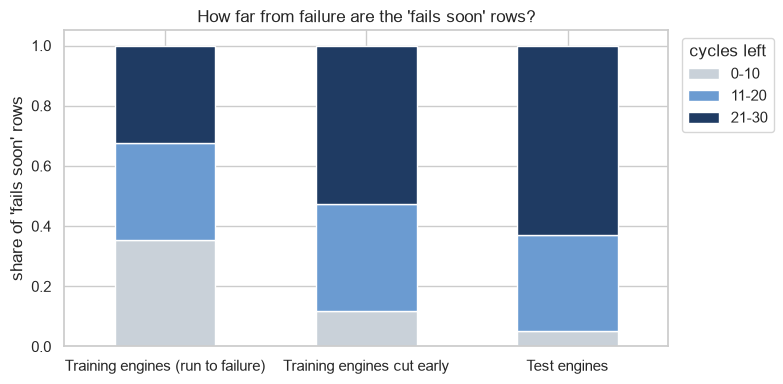

,Training engines (run to failure),Training engines cut early,Test engines
RUL,,,
0-10,0.35,0.12,0.05
11-20,0.32,0.36,0.32
21-30,0.32,0.53,0.63


In [3]:
# Validation engines cut early: 10 random cut points per engine, between cycle 31 and the end
# (31 = the shortest test engine). This is the fix explained in section 3; shown here for comparison.
last_rows, row_sets = truncation_index(train, k=10, min_cut=31, rng=np.random.default_rng(SEED))
cut_rows = np.concatenate(row_sets)

def where_positives_sit(df):
    pos = df[df["label"] == 1]
    return pd.cut(pos["RUL"], [-1, 10, 20, 30], labels=["0-10", "11-20", "21-30"]).value_counts(normalize=True).sort_index()

share = pd.DataFrame({
    "Training engines (run to failure)": where_positives_sit(train),
    "Training engines cut early": where_positives_sit(train.loc[cut_rows]),
    "Test engines": where_positives_sit(test),
})
ax = share.T.plot(kind="bar", stacked=True, figsize=(8, 4), rot=0, color=["#c9d1d9", "#6b9bd1", "#1f3b63"])
ax.set_ylabel("share of 'fails soon' rows"); ax.set_title("How far from failure are the 'fails soon' rows?")
ax.legend(title="cycles left", bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()
share.round(2)

**Reading the chart:** in the training engines about **32%** of the "fails soon" rows are the hard 21–30 cases; in the test engines it is about **63%**. Validating on whole training engines tested the model mostly on easy cases, while the test set is mostly hard ones.

Cutting the training engines early (middle bar) moves the mix much closer to the test set. That is the fix.

## 3. The fix: validation that looks like the test set, repeated 5 times

Two changes to how models are scored. **The models and features stay exactly as in Stage 1.**

1. **Cut validation engines early.** Cross-validation still holds out whole engines (5 folds of 20). Each held-out engine is cut at **10 random points** between cycle 31 and its end, and the model is scored on the rows up to each cut, just as the test engines end at an unknown point. No test labels are used.
2. **Repeat with 5 random seeds** (42–46). The seed changes which engines land in which fold and where the cuts fall. Results are reported as **mean ± standard deviation**, so we can tell a real difference from luck.

First, a live check with logistic regression and the Stage 1 window of 5 cycles:

In [4]:
def out_of_fold(window, model="logistic_regression", seed=SEED, kinds=("raw", "mean", "std")):
    """Grouped 5-fold CV: every training row is predicted by a model that never saw its engine."""
    P = np.zeros(len(train))
    for tr, va in grouped_folds(train["unit"].values, 5, seed):
        m = make_classifier(model, with_window(window, kinds), seed).fit(train.iloc[tr], train["label"].iloc[tr])
        P[va] = m.predict_proba(train.iloc[va])[:, 1]
    return P

y = train["label"].values
P5 = out_of_fold(5)
base_test = make_classifier("logistic_regression", with_window(5), SEED).fit(train, train["label"])
print(f"Validation F1, whole engines (as in Stage 1): {clf_metrics(y, P5)['f1']:.3f}")
print(f"Validation F1, engines cut early (Stage 2):    {clf_metrics(y[cut_rows], P5[cut_rows])['f1']:.3f}")
print(f"Test F1 (100 unseen engines):                  {clf_metrics(test['label'], base_test.predict_proba(test)[:, 1])['f1']:.3f}")

Validation F1, whole engines (as in Stage 1): 0.862
Validation F1, engines cut early (Stage 2):    0.722
Test F1 (100 unseen engines):                  0.706


The cut-early validation score (0.72) lands right next to the test score (0.71). **Validation now predicts the test result without looking at the test set.**

The same comparison for all four models, over 5 repeats (from `results.csv`):

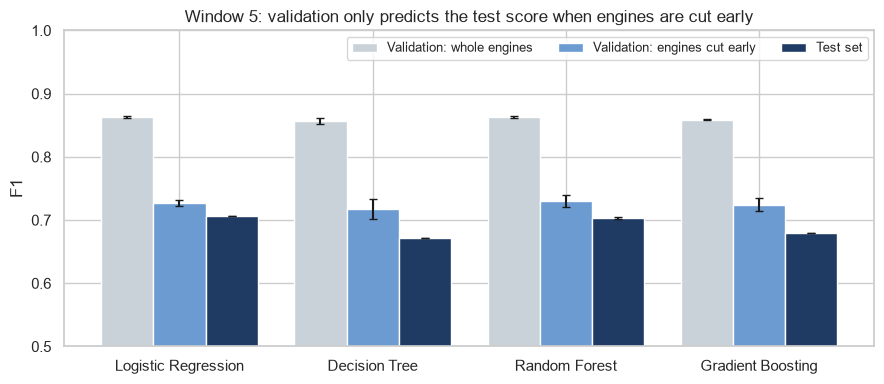

split,Validation: whole engines,Validation: engines cut early,Test set
model,,,
Logistic Regression,0.863 ± 0.002,0.728 ± 0.005,0.706 ± 0.000
Decision Tree,0.856 ± 0.005,0.718 ± 0.015,0.671 ± 0.000
Random Forest,0.863 ± 0.002,0.730 ± 0.009,0.703 ± 0.002
Gradient Boosting,0.859 ± 0.001,0.724 ± 0.010,0.680 ± 0.000


In [5]:
cb = res[res.experiment == "corrected_baseline"]
splits = {"cv_grouped5_shuffled_allrows_oof": "Validation: whole engines",
          "cv_grouped5_truncated_rows_oof": "Validation: engines cut early",
          "test_all_rows": "Test set"}
cb = cb[cb.split.isin(list(splits))]
cb_table = (cb.groupby(["model", "split"]).f1.agg(mean_sd).unstack()
            .loc[ORDER, list(splits)].rename(index=NICE, columns=splits))

g = cb.groupby(["model", "split"]).f1.agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(ORDER))
for i, (sp, lab) in enumerate(splits.items()):
    d = g[g.split == sp].set_index("model").loc[ORDER]
    ax.bar(x + (i - 1) * 0.27, d["mean"], 0.27, yerr=d["std"], capsize=3, label=lab,
           color=["#c9d1d9", "#6b9bd1", "#1f3b63"][i])
ax.set_xticks(x, [NICE[m] for m in ORDER]); ax.set_ylim(0.5, 1.0); ax.set_ylabel("F1")
ax.set_title("Window 5: validation only predicts the test score when engines are cut early")
ax.legend(ncol=3, fontsize=9, loc="upper right"); plt.tight_layout(); plt.show()
cb_table

**Two findings:**
- For **every** model, cut-early validation (0.72–0.73) matches the test set (0.67–0.71), while whole-engine validation (0.86) does not.
- **The four models are tied.** Their scores overlap within the ± spread. Stage 1 chose the random forest because it was ahead by 0.005 in one run; with repeats, that difference disappears.

## 4. Two checks before improving anything

### 4a. Did any information leak from the future or from other engines?

A leak would make every score too optimistic. The Stage 2 audit checked each place where one could happen (`python src/run_phase1_2.py checks`, run from `improved_implementation/`):

| Check | Result |
|---|---|
| Train and test engines are separate; cross-validation holds out whole engines | OK |
| The rolling window never mixes two engines (first-cycle mean = raw value for every engine) | OK |
| The rolling window never uses future cycles (see the live check below) | OK |
| Drop rule re-fitted inside each fold picks the same 14 sensors | Same in 25 of 25 folds |
| Scaler fitted on training folds only (inside the pipeline) | OK |

Live check that the features only use the past: compute engine 1's 40-cycle features with its whole history, then again with everything after cycle 100 deleted. If the features at cycles 1–100 are identical, the future was never used.

In [6]:
raw_cols = ["unit", "cycle"] + SENSORS
engine1 = train.loc[train["unit"] == 1, raw_cols]
feat40 = [f"{s}_{k}40" for s in SENSORS for k in ("mean", "std")]
full_history = add_rolling(engine1, SENSORS, 40)[feat40].iloc[:100].values
first_100_only = add_rolling(engine1[engine1["cycle"] <= 100], SENSORS, 40)[feat40].values
print("Features at cycles 1-100 identical with and without the later cycles:", np.allclose(full_history, first_100_only))

Features at cycles 1-100 identical with and without the later cycles: True


### 4b. Was the hyperparameter tuning in notebooks 4–5 finding anything real?

Notebooks 4 and 5 picked settings with `GridSearchCV` and reported the best score **on the same folds** it was picked on, which is slightly optimistic. **Nested cross-validation** fixes this: an outer loop holds back engines that the tuning never sees. It was run once (seed 42, about 30 minutes):

In [7]:
nest = res[res.experiment == "nested_cv_selection_bias"].set_index("model")
fixed = res[(res.experiment == "corrected_baseline") & (res.seed == 42)
            & (res.split == "cv_grouped5_shuffled_allrows_oof")].set_index("model")["f1"]
pd.DataFrame({
    "Tuned, scored on the same folds": nest["train_f1"],
    "Tuned, honest (nested)": nest["f1"],
    "No tuning (Stage 1 settings fixed)": fixed,
    "Different 'best' settings picked in 5 tries": nest["notes"].str.extract(r"outer folds: (\d+)")[0].astype(int),
}).loc[ORDER].rename(index=NICE).round(3)

,"Tuned, scored on the same folds","Tuned, honest (nested)",No tuning (Stage 1 settings fixed),Different 'best' settings picked in 5 tries
model,,,,
Logistic Regression,0.865,0.861,0.862,5
Decision Tree,0.850,0.860,0.862,3
Random Forest,0.867,0.865,0.861,5
Gradient Boosting,0.863,0.857,0.858,4


**Reading the table:**
- The optimism from scoring on the same folds is small (at most 0.005).
- The search picked a **different "best" setting almost every time**, and the tuned models scored **no better** than simply fixing the Stage 1 settings. The grids are **flat**: with only 100 engines, the data cannot tell these settings apart.

**Decision:** keep the Stage 1 hyperparameters (logistic regression: C = 0.01, L2 penalty) and look for the improvement somewhere else: in the features.

## 5. The improvement: a longer rolling window

**What the baseline misses.** Its errors are the engines 21–30 cycles from failure. Their sensors are only starting to drift, and the drift is slow.

**Why 5 cycles is too short.** Notebook 3 chose 5 as "small enough to react quickly, large enough to smooth noise", but it was never tested. Over 5 cycles, a slow drift is hidden by the noise. Compare the 5-cycle and 40-cycle spread of sensor s11 (compressor pressure, the strongest sensor) over the life of one training engine:

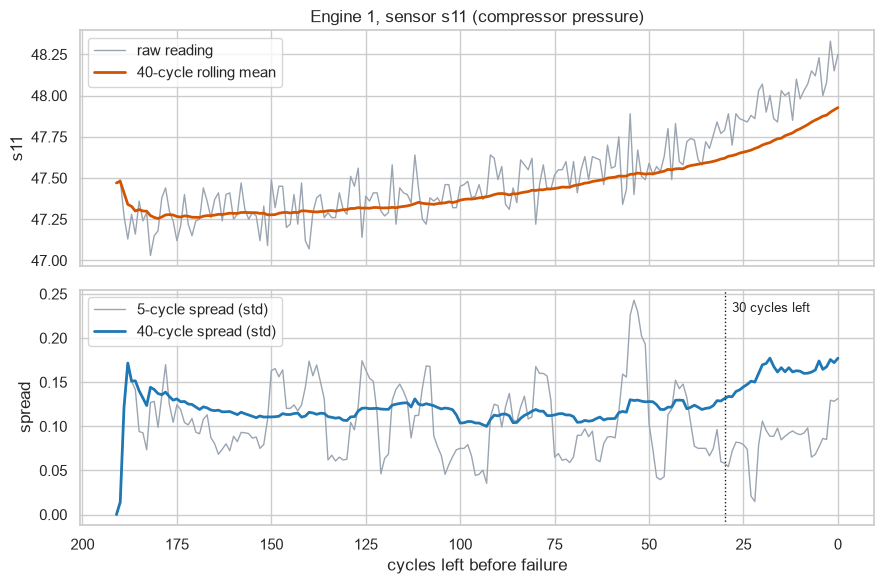

In [8]:
eng = train[train["unit"] == 1]
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(eng["RUL"], eng["s11"], color="#9aa5b1", lw=1, label="raw reading")
axes[0].plot(eng["RUL"], eng["s11_mean40"], color="#d35400", lw=2, label="40-cycle rolling mean")
axes[0].set_ylabel("s11"); axes[0].legend(); axes[0].set_title("Engine 1, sensor s11 (compressor pressure)")
axes[1].plot(eng["RUL"], eng["s11_std5"], color="#9aa5b1", lw=1, label="5-cycle spread (std)")
axes[1].plot(eng["RUL"], eng["s11_std40"], color="#1f77b4", lw=2, label="40-cycle spread (std)")
axes[1].axvline(30, color="k", ls=":", lw=1); axes[1].text(28, axes[1].get_ylim()[1] * 0.9, "30 cycles left", fontsize=9, ha="left")
axes[1].set_ylabel("spread"); axes[1].set_xlabel("cycles left before failure"); axes[1].legend()
axes[1].invert_xaxis()                      # shared x-axis: failure (0 cycles left) on the right
plt.tight_layout(); plt.show()

- **5-cycle spread (grey):** jumps around the whole life. Five readings are mostly noise, so a healthy engine and a failing one look alike.
- **40-cycle spread (blue):** low and flat while the engine is healthy, then rises steadily as the sensor starts drifting. **It measures how fast the engine is wearing.** (The jump at the very start only happens because a brand-new engine has just a few readings to work with.)

### The window study

We tried 5, 10, 20, 30, 40 and 50 cycles for all four models, scored with cut-early validation and 5 repeats each. **No test data was used.**

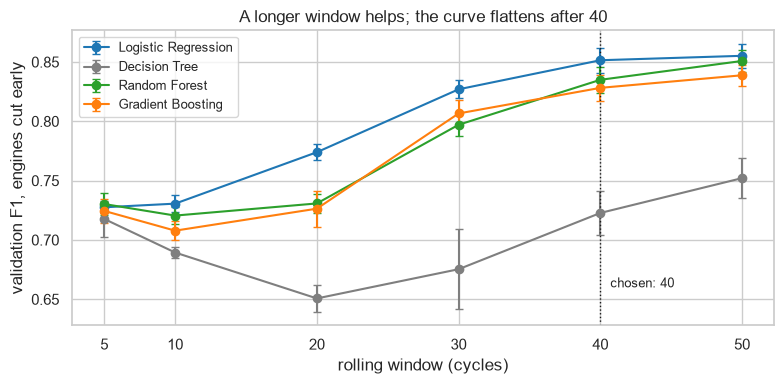

model,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting
window,,,,
5,0.728 ± 0.005,0.718 ± 0.015,0.730 ± 0.009,0.724 ± 0.010
10,0.731 ± 0.007,0.689 ± 0.005,0.721 ± 0.007,0.708 ± 0.008
20,0.774 ± 0.007,0.651 ± 0.011,0.731 ± 0.008,0.726 ± 0.015
30,0.827 ± 0.008,0.675 ± 0.034,0.797 ± 0.010,0.807 ± 0.012
40,0.851 ± 0.011,0.723 ± 0.019,0.835 ± 0.011,0.828 ± 0.011
50,0.855 ± 0.010,0.752 ± 0.017,0.851 ± 0.009,0.839 ± 0.009


In [9]:
wa = res[(res.experiment == "window_ablation") & (res.split == "cv_grouped5_truncated_rows_oof")].copy()
wa["window"] = wa["config"].map(lambda c: json.loads(c)["window"])

fig, ax = plt.subplots(figsize=(8, 4))
for m in ORDER:
    g = wa[wa.model == m].groupby("window")["f1"].agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3, label=NICE[m], color=COL[m])
ax.axvline(40, color="k", ls=":", lw=1); ax.text(40.7, 0.66, "chosen: 40", fontsize=9)
ax.set_xticks([5, 10, 20, 30, 40, 50]); ax.set_xlabel("rolling window (cycles)")
ax.set_ylabel("validation F1, engines cut early"); ax.set_title("A longer window helps; the curve flattens after 40")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

wa.groupby(["window", "model"])["f1"].agg(mean_sd).unstack()[ORDER].rename(columns=NICE)

**How 40 was chosen:**
- Logistic regression rises from **0.728** (window 5) to **0.851** (window 40), more than ten standard deviations.
- Going to 50 adds only 0.004, **less than one standard deviation** (±0.010): no real improvement. We take the **shortest window that reaches the plateau**. A shorter window also needs less history.
- (The first study stopped at 30; because 30 was the best, it was extended to 40 and 50 until the curve flattened.)

Live check: the logistic regression number for window 40, seed 42, recomputed from scratch:

In [10]:
P40 = out_of_fold(40)
logged = wa[(wa.model == "logistic_regression") & (wa.window == 40) & (wa.seed == SEED)]["f1"].iloc[0]
live = clf_metrics(y[cut_rows], P40[cut_rows])["f1"]
print(f"Window 40, engines cut early: live {live:.4f} | results.csv {logged:.4f}")

Window 40, engines cut early: live 0.8590 | results.csv 0.8590


## 6. Why it works: which features carry the signal?

At window 40, remove one feature type at a time and score again (5 repeats, engines cut early):

In [11]:
fa = res[(res.experiment == "feature_set_ablation") & (res.split == "cv_grouped5_truncated_rows_oof")].copy()
fa["features"] = fa["config"].map(lambda c: " + ".join(json.loads(c)["kinds"]))
fa["features"] = fa["features"].replace({"raw + mean + std": "raw + mean + spread (all 42)",
                                         "raw + mean": "raw + mean (no spread)", "mean": "mean only"})
fa.groupby(["features", "model"])["f1"].agg(mean_sd).unstack()[ORDER].rename(columns=NICE) \
  .loc[["raw + mean + spread (all 42)", "raw + mean (no spread)", "mean only"]]

model,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting
features,,,,
raw + mean + spread (all 42),0.851 ± 0.011,0.723 ± 0.019,0.835 ± 0.011,0.828 ± 0.011
raw + mean (no spread),0.749 ± 0.003,0.671 ± 0.015,0.731 ± 0.007,0.741 ± 0.005
mean only,0.599 ± 0.012,0.560 ± 0.019,0.566 ± 0.020,0.578 ± 0.007


- Removing the **spread** features costs logistic regression about **0.10** F1 (0.851 → 0.749).
- Removing the **raw** reading as well costs another **0.15** (→ 0.599).

**The 40-cycle spread is what makes the improvement work.** It catches drift in **either direction**: a rising sensor and a falling one both have a large spread. This matters for the core-speed sensors s9 and s14, which rise in some engines and fall in others.

## 7. Which model, and which settings?

### 7a. The model

At window 40, all four models compared on their training engines and on held-out engines (5 repeats):

In [12]:
w40 = res[(res.experiment == "window_ablation") & res["config"].str.contains('"window": 40', na=False)]
whole = w40[w40.split == "cv_grouped5_shuffled_allrows_oof"].groupby("model")[["train_f1", "f1"]].mean()
cut = w40[w40.split == "cv_grouped5_truncated_rows_oof"].groupby("model")["f1"].agg(mean_sd)
pd.DataFrame({"Train F1": whole["train_f1"].round(3), "Validation F1 (whole engines)": whole["f1"].round(3),
              "Gap (overfitting)": (whole["train_f1"] - whole["f1"]).round(3),
              "Validation F1 (cut early)": cut}).loc[ORDER].rename(index=NICE)

,Train F1,Validation F1 (whole engines),Gap (overfitting),Validation F1 (cut early)
model,,,,
Logistic Regression,0.932,0.925,0.007,0.851 ± 0.011
Decision Tree,0.913,0.871,0.042,0.723 ± 0.019
Random Forest,0.991,0.917,0.074,0.835 ± 0.011
Gradient Boosting,0.991,0.915,0.077,0.828 ± 0.011


**Logistic regression is the choice:**
- **Best or tied-best at every window length** (section 5). The random forest catches up at 50 but never passes it.
- **Smallest gap** between training and validation (0.007, against 0.07 for the random forest and gradient boosting): it does not memorise.
- **Simplest:** 127 learned numbers, against about 98,000 tree nodes for the random forest, and its weights can be read directly (section 9).

When a simple model ties a complex one, the simple one wins.

### 7b. The decision threshold

The model outputs a probability; above the threshold we say "fails soon". Notebook 5 lowered it to about 0.33 to catch more failures. In Stage 2 the threshold was picked on cut-early validation (one per repeat):

In [13]:
fi = res[(res.experiment == "final_improved") & res.split.str.startswith("cv_grouped5_truncated_rows_oof", na=False)].copy()
fi["rule"] = fi.split.str.split("|").str[1].map({"thr0.5": "0.5 (default)",
                                                 "thr_maxF1_truncCV": "best F1 on validation",
                                                 "thr_recall90_truncCV": "90% recall on validation"})
fi.groupby("rule")[["threshold", "f1", "recall", "precision"]].agg(mean_sd)

,threshold,f1,recall,precision
rule,,,,
0.5 (default),0.500 ± 0.000,0.851 ± 0.011,0.863 ± 0.022,0.841 ± 0.007
90% recall on validation,0.449 ± 0.028,0.846 ± 0.011,0.900 ± 0.000,0.799 ± 0.019
best F1 on validation,0.509 ± 0.041,0.856 ± 0.008,0.862 ± 0.013,0.850 ± 0.025


The threshold with the best F1 comes out at **0.51 ± 0.04**: effectively 0.5. Aiming for 90% recall gives about 0.45. All three give the same F1 within the noise, so the default **0.5** is kept.

### 7c. Final settings (hyperparameters, chosen by us before training)

| Hyperparameter | Value | How it was chosen |
|---|---|---|
| Label | "fails soon" = 30 or fewer cycles left | Design choice: a realistic planning window (Stage 1) |
| Drop rule | drop columns with std < 0.01 → 14 sensors kept | Stage 1 rule, now fitted inside each fold |
| Rolling window | **40 cycles** | Window study (section 5) |
| Features | raw + 40-cycle mean + 40-cycle spread, 14 sensors → 42 | Feature study (section 6) |
| Model | logistic regression | Section 7a |
| C (penalty strength) | 0.01 | Stage 1 grid search; nested CV showed the grid is flat (section 4b) |
| Penalty type | L2 | Stage 1 grid search; shares weight across sensors that move together |
| Class weight | none | Stage 1 grid search ("balanced" lowered F1) |
| Threshold | 0.5 | Section 7b |

### 7d. Train the final model and count what it learned (parameters)

The model is trained once on all 100 training engines (about 0.15 seconds):

In [14]:
final_model = make_classifier("logistic_regression", with_window(40), SEED).fit(train, train["label"])
select, scaler, clf = final_model["select"], final_model["scale"], final_model["clf"]

print("Features used:                  ", len(select.columns_), "(14 sensors x raw, 40-cycle mean, 40-cycle spread)")
print("Weights (one per feature):      ", clf.coef_.size)
print("Intercept (starting point):     ", clf.intercept_.size, f"-> value {clf.intercept_[0]:.3f}")
print("Scaling numbers (avg + spread): ", scaler.mean_.size + scaler.scale_.size)
print("Total learned numbers:          ", n_params(final_model))

Features used:                   42 (14 sensors x raw, 40-cycle mean, 40-cycle spread)
Weights (one per feature):       42
Intercept (starting point):      1 -> value -3.547
Scaling numbers (avg + spread):  84
Total learned numbers:           127


- **Scaling numbers (84):** the average and spread of each feature over the training rows. Each feature is turned into "how many spreads from normal", so all 42 are on the same ruler.
- **Weights (42):** how strongly each feature pushes toward "fails soon".
- **Intercept (1):** the starting point. It is strongly negative because most rows are healthy: an average row starts at about a 3% chance of failure.

## 8. The test set, scored once

Every choice above was made with training engines only. The test set was scored **once**, after all of them were fixed, and the result was logged in `results.csv`. The cell below recomputes it and checks that it matches.

Two views, as in notebook 5:
- **All rows:** every cycle of every test engine (13,096 rows, 332 of them "fails soon").
- **One decision per engine:** at each engine's last available cycle, "should this engine go for maintenance now?" (25 yes, 75 no). This is how the model would be used.

In [15]:
last_idx = test.groupby("unit")["cycle"].idxmax()          # row of each engine's last available cycle
models = {"Stage 1 baseline (window 5)": base_test, "Stage 2 final (window 40)": final_model}
rows = {}
for name, m in models.items():
    p = m.predict_proba(test)[:, 1]
    test[name] = p
    on_rows, per_engine = clf_metrics(test["label"], p), clf_metrics(test.loc[last_idx, "label"], p[last_idx.values])
    eng = test.loc[last_idx, ["unit", "label", "RUL"]].assign(flag=p[last_idx.values] >= 0.5)
    rows[name] = {"F1 (all rows)": on_rows["f1"], "Recall (all rows)": on_rows["recall"],
                  "Precision (all rows)": on_rows["precision"],
                  "Failing engines caught (of 25)": int((eng.flag & (eng.label == 1)).sum()),
                  "False alarms (of 75 healthy)": int((eng.flag & (eng.label == 0)).sum()),
                  "Wrong decisions (of 100)": int((eng.flag != (eng.label == 1)).sum())}
results = pd.DataFrame.from_dict(rows, orient="index")
logged = res[(res.experiment == "final_improved") & (res.seed == SEED) & (res.split == "test_all_rows|thr0.5")]["f1"].iloc[0]
print(f"Final model test F1 matches the logged result: {np.isclose(results.iloc[1, 0], logged)}")
results.round(3)

Final model test F1 matches the logged result: True


,F1 (all rows),Recall (all rows),Precision (all rows),Failing engines caught (of 25),False alarms (of 75 healthy),Wrong decisions (of 100)
Stage 1 baseline (window 5),0.706,0.627,0.809,18,1,8
Stage 2 final (window 40),0.870,0.867,0.873,25,1,1


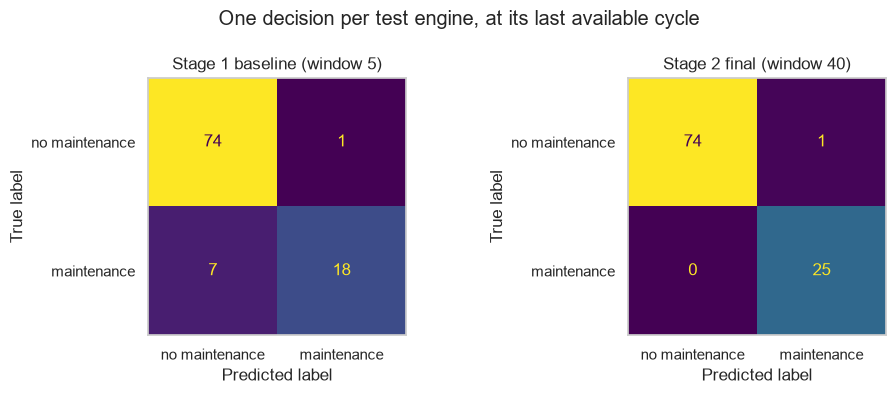

,model,engine,true cycles left,probability,error
0,Stage 1 baseline (window 5),18,28,0.160,missed failure
1,Stage 1 baseline (window 5),37,21,0.151,missed failure
2,Stage 1 baseline (window 5),41,18,0.137,missed failure
3,Stage 1 baseline (window 5),52,29,0.372,missed failure
4,Stage 1 baseline (window 5),53,26,0.375,missed failure
5,Stage 1 baseline (window 5),61,21,0.363,missed failure
6,Stage 1 baseline (window 5),64,28,0.366,missed failure
7,Stage 1 baseline (window 5),91,38,0.629,false alarm
8,Stage 2 final (window 40),77,34,0.616,false alarm


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, models):
    eng = test.loc[last_idx]
    ConfusionMatrixDisplay.from_predictions(eng["label"], (eng[name] >= 0.5).astype(int), ax=ax, colorbar=False,
                                            display_labels=["no maintenance", "maintenance"])
    ax.set_title(name); ax.grid(False)
plt.suptitle("One decision per test engine, at its last available cycle"); plt.tight_layout(); plt.show()

wrong = []
for name in models:
    eng = test.loc[last_idx]
    bad = eng[(eng[name] >= 0.5) != (eng["label"] == 1)]
    for _, r in bad.iterrows():
        wrong.append({"model": name, "engine": int(r.unit), "true cycles left": int(r.RUL),
                      "probability": round(r[name], 3), "error": "missed failure" if r.label == 1 else "false alarm"})
pd.DataFrame(wrong)

**Baseline: 8 wrong decisions.** Seven failing engines were missed, all **18–29 cycles** from failure: exactly the slow-drift cases a 5-cycle window cannot see. Plus one false alarm.

**Final model: 1 wrong decision.** Engine 77 is flagged with **34** cycles left, four cycles before it would count as "fails soon". That is an early warning, not a dangerous miss.

Where the gain comes from, for every "fails soon" test row grouped by how far it is from failure:

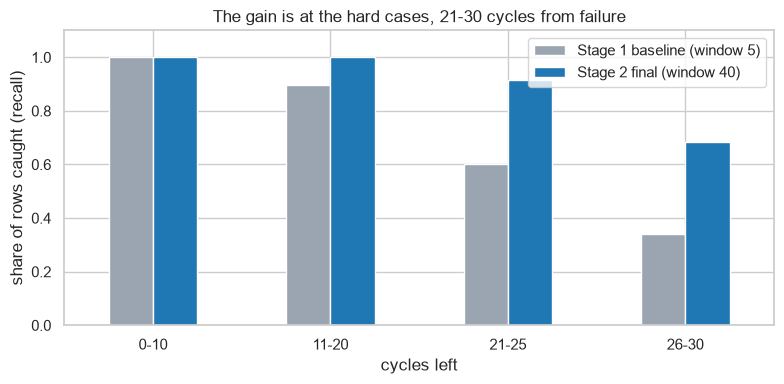

,Stage 1 baseline (window 5),Stage 2 final (window 40),rows
cycles left,,,
0-10,1.00,1.00,17
11-20,0.90,1.00,106
21-25,0.60,0.92,95
26-30,0.34,0.68,114


In [17]:
pos = test[test["label"] == 1].copy()
pos["cycles left"] = pd.cut(pos["RUL"], [-1, 10, 20, 25, 30], labels=["0-10", "11-20", "21-25", "26-30"])
caught = pd.DataFrame({name: (pos[name] >= 0.5).groupby(pos["cycles left"], observed=False).mean() for name in models})
caught["rows"] = pos.groupby("cycles left", observed=False).size()
ax = caught[list(models)].plot(kind="bar", figsize=(8, 4), rot=0, color=["#9aa5b1", "#1f77b4"])
ax.set_ylabel("share of rows caught (recall)"); ax.set_ylim(0, 1.1)
ax.set_title("The gain is at the hard cases, 21-30 cycles from failure"); plt.tight_layout(); plt.show()
caught.round(2)

Close to failure (0–20 cycles) both models catch almost everything. The difference is at **21–30 cycles left**, the hard cases that make up most of the test set's "fails soon" rows (section 2).

**A word of caution on "25 of 25".** The test set has only 25 failing engines, so one engine is 4 points of recall. Read it as "clearly better than 18 of 25", not "perfect in general". The cut-early validation estimate for one-decision-per-engine F1 is **0.92**, which is the figure to expect on new engines.

## 9. How the model decides

### 9a. One prediction, step by step

Test engine 34 at its last available cycle (cycle 203, truly 7 cycles from failure). For each feature: scale it, multiply by its weight, add everything up with the intercept, and turn the total into a probability:

In [18]:
row = test.loc[[last_idx[34]]]
scaled = (row[select.columns_].values[0] - scaler.mean_) / scaler.scale_    # "spreads from normal"
contrib = pd.Series(scaled * clf.coef_[0], index=select.columns_)
total = clf.intercept_[0] + contrib.sum()
prob = 1 / (1 + np.exp(-total))                                              # sigmoid

top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
display(pd.DataFrame({"scaled value": pd.Series(scaled, index=select.columns_)[top.index],
                      "weight": pd.Series(clf.coef_[0], index=select.columns_)[top.index],
                      "contribution": top}).round(2))
print(f"intercept {clf.intercept_[0]:.2f} + all 42 contributions {contrib.sum():.2f} = total {total:.2f}")
print(f"probability = {prob:.3f} (model says {final_model.predict_proba(row)[0, 1]:.3f}) -> "
      f"{'FAILS SOON' if prob >= 0.5 else 'healthy'}")

,scaled value,weight,contribution
s11_std40,3.68,0.51,1.88
s12_std40,3.60,0.44,1.59
s13_std40,3.56,0.34,1.21
s8_std40,2.64,0.28,0.73
s8,2.72,0.21,0.57


intercept -3.55 + all 42 contributions 11.33 = total 7.78
probability = 1.000 (model says 1.000) -> FAILS SOON


s11's 40-cycle spread is about 3.7 spreads above normal, and with its weight of 0.51 it alone adds almost +1.9. Several other compressor sensors are also drifting fast, so the total is far above zero and the probability is close to 1.

### 9b. What the model looks at overall

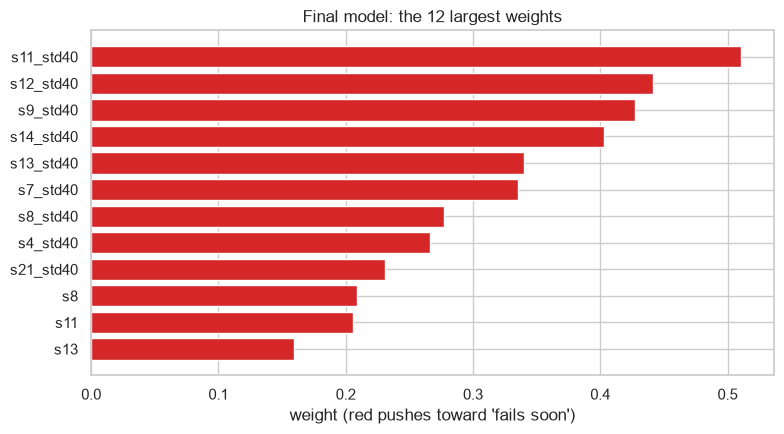

40-cycle mean      0.14
40-cycle spread    0.61
raw reading        0.26
Name: share of total weight, dtype: float64

In [19]:
w = pd.Series(clf.coef_[0], index=select.columns_)
top12 = w.reindex(w.abs().sort_values(ascending=False).index).head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top12.index, top12.values, color=["#d62728" if v > 0 else "#1f77b4" for v in top12.values])
ax.set_xlabel("weight (red pushes toward 'fails soon')"); ax.set_title("Final model: the 12 largest weights")
plt.tight_layout(); plt.show()

kind = w.index.to_series().map(lambda n: "40-cycle spread" if "_std" in n else "40-cycle mean" if "_mean" in n else "raw reading")
(w.abs().groupby(kind.values).sum() / w.abs().sum()).round(2).rename("share of total weight")

- **The 9 largest weights (and 10 of the top 12) are 40-cycle spreads, all positive:** the faster a sensor is changing, the closer the engine is to failure.
- **The top ones are s11 and s12**, pressure measurements at the high-pressure compressor (HPC). This matches the physics: FD001's only fault is HPC wear.
- Many of these sensors move together, so the **group** is reliable but the **order inside it** is not (one could swap with another on slightly different data).

## 10. Summary: Stage 1 vs Stage 2

| | Stage 1 (notebooks 1–5) | Stage 2 (this notebook) |
|---|---|---|
| Validation | Whole training engines, one run | Engines **cut early** like the test set, **5 repeats** |
| Validation predicts the test score? | No (0.87 vs 0.70) | Yes (0.85 vs 0.87) |
| Rolling window | 5 cycles (not tested) | **40 cycles** (tested 5–50) |
| Final model | Random forest, threshold ≈0.33 | **Logistic regression**, threshold 0.5 |
| Hyperparameters | Grid search | Same values; nested CV showed tuning adds nothing |
| Learned numbers | about 98,000 tree nodes | **127** |
| Test F1 (all rows) | 0.706 (logistic regression) | **0.870** |
| Failing engines caught (of 25) | 18 | **25** |
| Wrong decisions (of 100 engines) | 8 | **1** (an early warning at 34 cycles) |

The Stage 1 test numbers are for logistic regression at window 5, so the last three rows compare the same model and settings with only the window changed.

**The two lessons:** test the model the way it will really be used, and give it enough history to see the trend.

### Limitations
- **Only 25 failing test engines:** engine-level percentages are coarse (one engine = 4 points).
- **Only FD001:** one flight condition and one fault type. FD002–FD004 would need normalising per flight condition.
- **Simulated data:** real engines have more noise, missing readings and repair history.
- **Engines younger than 31 cycles** were never in validation (the shortest test engine has 31), so the model is untested on them.
- **Not tried:** neural networks, or predicting the exact number of cycles left.

## Likely viva questions
- *Why did the validation score drop from 0.87 to 0.70 on the test set?* → Test engines stop before failure, so their "fails soon" rows are mostly the hard 21–30-cycle cases (63% vs 32% in training). Whole-engine validation tested mostly easy cases.
- *How did you fix validation without using the test labels?* → Each held-out training engine is cut at 10 random points between cycle 31 and its end, mimicking how the test engines were cut. Only training data is used.
- *Why repeat 5 times?* → With 100 engines, results move with the random split. The ± spread tells us whether a difference is real. Stage 1's random forest "win" (0.005) was not.
- *Why 40 cycles and not 50?* → 50 adds 0.004, less than one standard deviation. We take the shortest window that reaches the plateau.
- *Why does a longer window help?* → The sensors drift slowly. Over 40 cycles a drifting sensor has a clearly larger spread than a steady one, so the spread measures how fast the engine is wearing. Remove the spread features and F1 drops by 0.10.
- *Isn't a 40-cycle window cheating?* → No. It only uses the current and earlier cycles of the same engine; the live check in section 4a shows the future is never used.
- *Why logistic regression over the random forest?* → Best or tied at every window, smallest train-validation gap, 127 readable numbers instead of about 98,000 tree nodes.
- *Why not re-tune the hyperparameters at window 40?* → Nested CV showed the grids are flat: tuning picked a different "best" each time and scored no better than fixed settings.
- *Is 25 of 25 perfect?* → No. With 25 failing engines one engine is 4 points. The validation estimate for new engines is F1 0.92 per engine.
- *Why is the one mistake acceptable?* → It is a false alarm on an engine 34 cycles from failure: an early warning, not a missed failure.